In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [32]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bitext/training-dataset-for-chatbotsvirtual-assistants")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'training-dataset-for-chatbotsvirtual-assistants' dataset.
Path to dataset files: /kaggle/input/training-dataset-for-chatbotsvirtual-assistants


In [33]:
files = os.listdir(path)
print("Dataset files:", files)

Dataset files: ['Bitext_Sample_Customer_Service_Training_Dataset', '20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample']


In [34]:
# Find all CSV files recursively
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))

print("CSV Files:", csv_files)

CSV Files: ['/kaggle/input/training-dataset-for-chatbotsvirtual-assistants/Bitext_Sample_Customer_Service_Training_Dataset/Training/Bitext_Sample_Customer_Service_Training_Dataset.csv', '/kaggle/input/training-dataset-for-chatbotsvirtual-assistants/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv']


In [35]:
df = pd.read_csv(csv_files[0])
df.head()

,flags,utterance,category,intent
0,BM,I have problems with canceling an order,ORDER,cancel_order
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order
2,B,I need help with canceling the last order,ORDER,cancel_order
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order
4,B,problem with cancelling an order I made,ORDER,cancel_order


In [36]:
df.shape

(8175, 4)

In [37]:
df.columns


Index(['flags', 'utterance', 'category', 'intent'], dtype='object')

In [38]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8175 entries, 0 to 8174
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   flags      8175 non-null   object
 1   utterance  8175 non-null   object
 2   category   8175 non-null   object
 3   intent     8175 non-null   object
dtypes: object(4)
memory usage: 255.6+ KB


In [39]:
# Statistical summary
df.describe(include="all")

,flags,utterance,category,intent
count,8175,8175,8175,8175
unique,118,8175,11,27
top,B,I have problems with canceling an order,ACCOUNT,check_invoice
freq,2395,1,1774,324


In [40]:
df.isnull().sum()

,0
flags,0
utterance,0
category,0
intent,0


In [41]:
print("Total duplicates:", df.duplicated().sum())

Total duplicates: 0


In [42]:
df["category"].nunique()

11

In [43]:
df["intent"].nunique()

27

In [44]:
df["category"].value_counts()

,count
category,
ACCOUNT,1774
ORDER,1220
REFUND,904
INVOICE,648
PAYMENT,620
FEEDBACK,613
SHIPPING_ADDRESS,604
DELIVERY,603
CONTACT,596


In [45]:
df["intent"].value_counts()

,count
intent,
check_invoice,324
get_invoice,324
payment_issue,323
review,315
track_refund,308
set_up_shipping_address,307
place_order,306
cancel_order,305
track_order,305


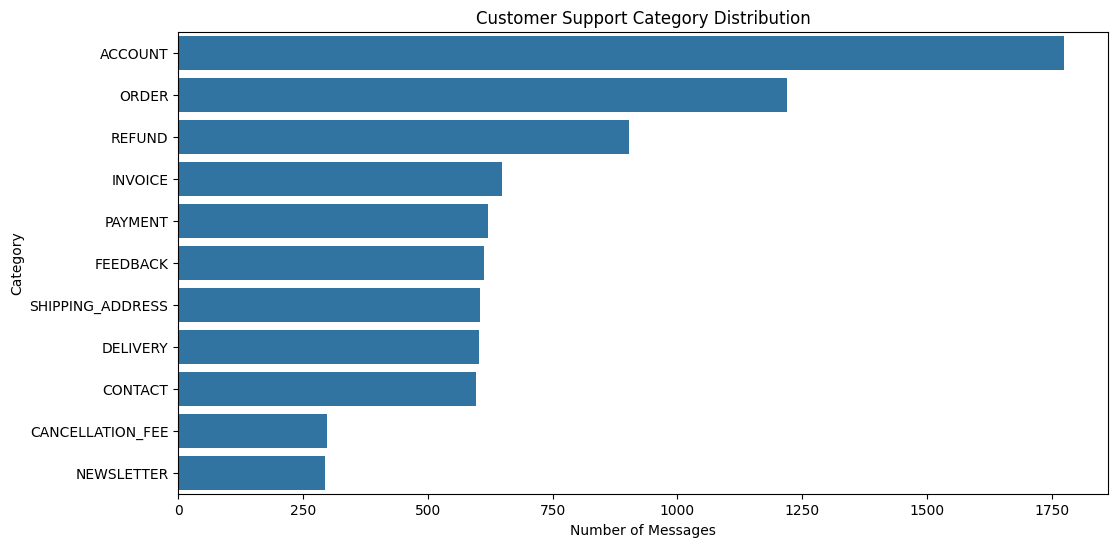

In [46]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)

plt.title("Customer Support Category Distribution")
plt.xlabel("Number of Messages")
plt.ylabel("Category")
plt.show()

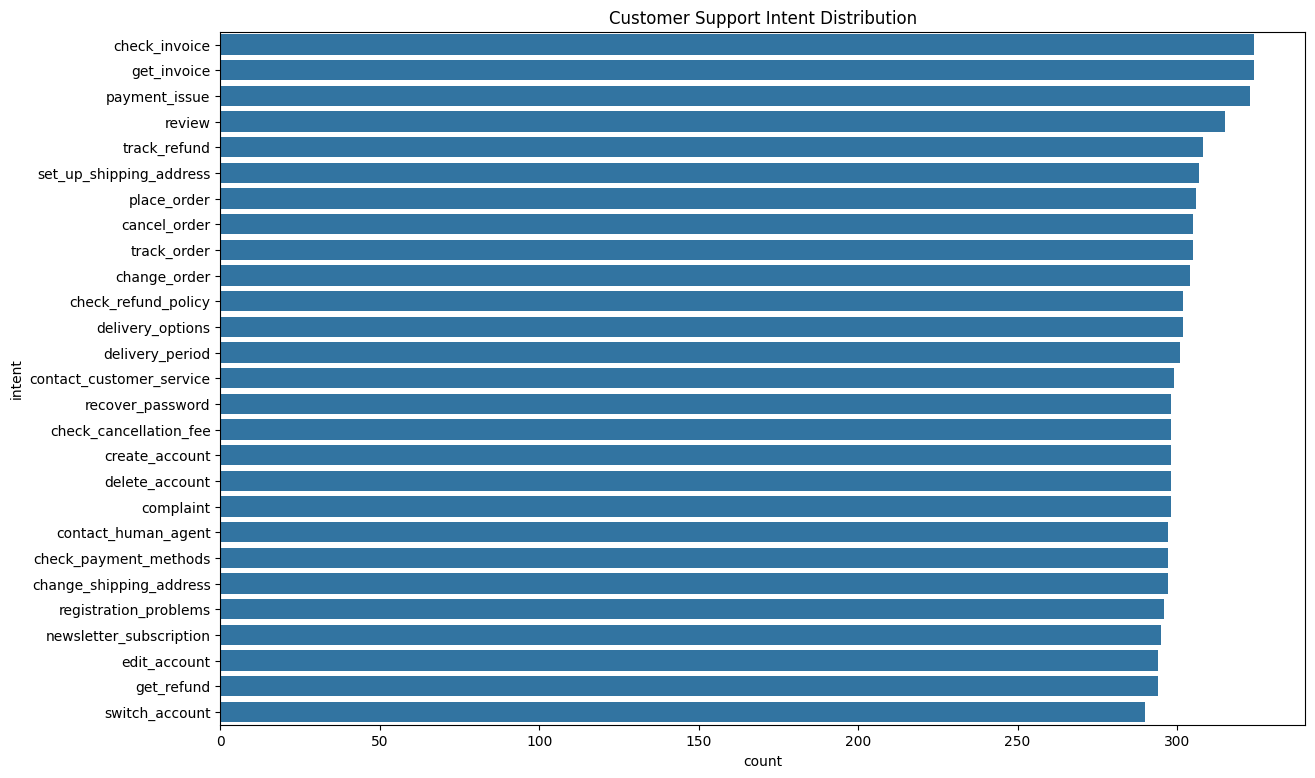

In [47]:
plt.figure(figsize=(14, 9))

sns.countplot(
    data=df,
    y="intent",
    order=df["intent"].value_counts().index
)

plt.title("Customer Support Intent Distribution")
plt.show()

In [48]:
df["text_length"] = df["utterance"].astype(str).apply(
    lambda x: len(x.split())
)

print(df["text_length"].describe())

count    8175.000000
mean        8.323914
std         2.386044
min         1.000000
25%         7.000000
50%         8.000000
75%        10.000000
max        15.000000
Name: text_length, dtype: float64


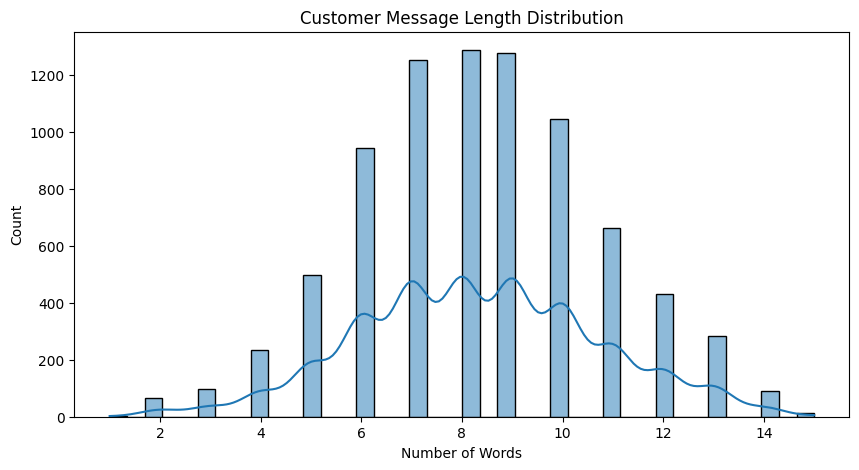

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["text_length"],
    bins=40,
    kde=True
)

plt.title("Customer Message Length Distribution")
plt.xlabel("Number of Words")
plt.show()

In [50]:
from collections import Counter
import re

all_words = " ".join(
    df["utterance"].astype(str)
).lower()

words = re.findall(r"\b[a-z]+\b", all_words)

word_counts = Counter(words)

print(word_counts.most_common(30))

[('i', 6082), ('to', 4857), ('the', 2157), ('help', 2109), ('a', 1617), ('do', 1574), ('my', 1551), ('can', 1528), ('me', 1507), ('how', 1391), ('check', 1267), ('what', 1167), ('need', 1078), ('know', 1038), ('you', 1015), ('assistance', 900), ('account', 891), ('could', 846), ('order', 828), ('have', 817), ('want', 817), ('an', 804), ('your', 694), ('address', 604), ('not', 564), ('with', 562), ('get', 553), ('for', 551), ('of', 536), ('shipping', 531)]


In [51]:
df.to_csv(
    "/content/sample_data/support_tickets.csv",
    index=False
)

print("Raw dataset saved successfully!")


Raw dataset saved successfully!
